## Exploratory Data Analysis & Visualization

In [1]:
# Ensure working directory is set to project root
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Imports for data processing, math operations, plotting, and file handling
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure output directory for saving figures exists
os.makedirs("visualizations", exist_ok=True)

# Load engineered dataset
engineered_csv_path = "data/processed/utkface_engineered.csv"
df = pd.read_csv(engineered_csv_path)

print(f"Loaded {len(df)} rows from '{engineered_csv_path}'.")
print("Output visualization directory 'visualizations/' ready.")

Loaded 2998 rows from 'data/processed/utkface_engineered.csv'.
Output visualization directory 'visualizations/' ready.


=== AGE DISTRIBUTION SUMMARY STATISTICS ===
count    2998.000000
mean       33.414943
std        20.274096
min         1.000000
25%        23.000000
50%        29.000000
75%        45.000000
max       110.000000
Name: age, dtype: float64


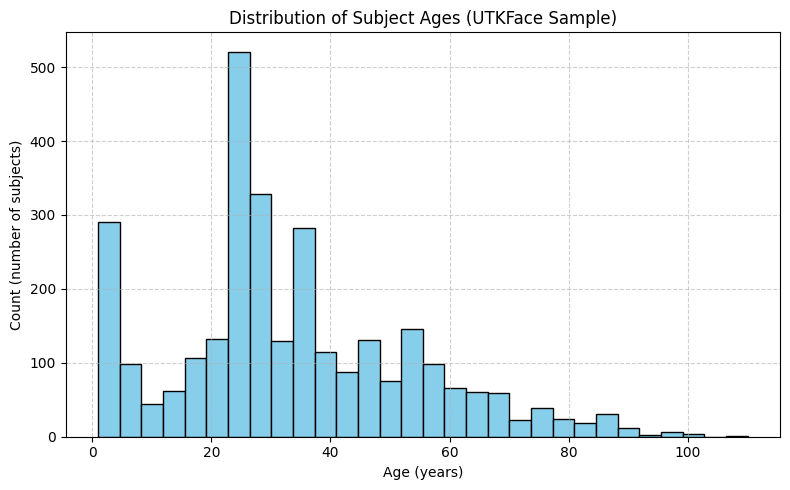

In [2]:
# Print summary statistics for target variable 'age'
print("=== AGE DISTRIBUTION SUMMARY STATISTICS ===")
print(df['age'].describe())

# Plot Histogram for Age Distribution
plt.figure(figsize=(8, 5))
plt.hist(df['age'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Subject Ages (UTKFace Sample)')
plt.xlabel('Age (years)')
plt.ylabel('Count (number of subjects)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Save figure to PNG
plt.savefig("visualizations/01_age_distribution.png", dpi=150)
plt.show()

### Observation: Age Distribution

*Placeholder for user observations on the Age Distribution histogram and summary statistics:*
- [Fill in observations regarding central tendency (mean = 33.46, median = 30.0), spread (std = 20.32, range = 1 to 115), and histogram shape/skewness after inspecting the plot.]

=== GENDER CATEGORY VALUE COUNTS ===
gender_label
Male (0)      1584
Female (1)    1414
Name: count, dtype: int64


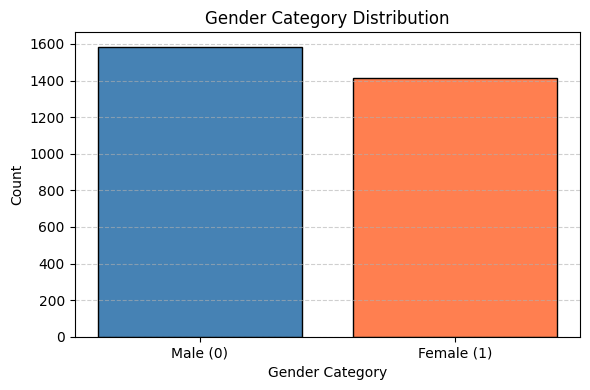

In [3]:
# Reconstruct readable gender label column for visualization purposes only
df['gender_label'] = np.where(df['gender_0'] == 1, 'Male (0)', 'Female (1)')

# Print exact value counts for gender
print("=== GENDER CATEGORY VALUE COUNTS ===")
gender_counts = df['gender_label'].value_counts()
print(gender_counts)

# Plot Bar Chart for Gender Distribution
plt.figure(figsize=(6, 4))
plt.bar(gender_counts.index, gender_counts.values, color=['steelblue', 'coral'], edgecolor='black')
plt.title('Gender Category Distribution')
plt.xlabel('Gender Category')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# Save figure to PNG
plt.savefig("visualizations/02_gender_distribution.png", dpi=150)
plt.show()

### Observation: Gender Distribution

*Placeholder for user observations on Gender Distribution:*
- [Fill in observations regarding category balance (Male: 1,576 vs Female: 1,422) after inspecting the bar chart and value counts.]

=== RACE CATEGORY VALUE COUNTS ===
race_label
Race_0    1293
Race_1     559
Race_2     442
Race_3     495
Race_4     209
Name: count, dtype: int64


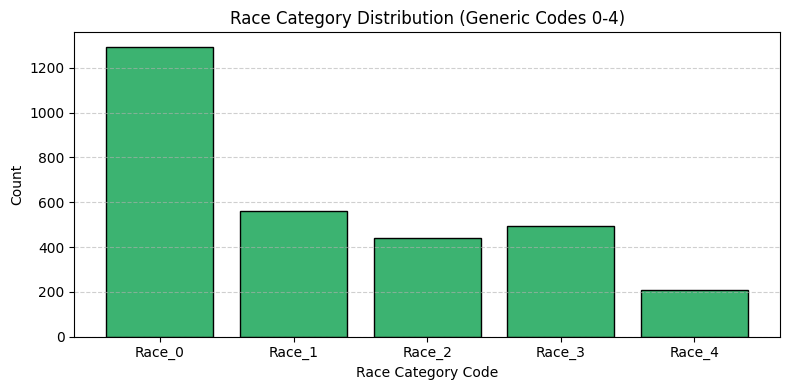

In [4]:
# Reconstruct readable race label column (Race_0 through Race_4 generically)
def get_race_label(row):
    for i in range(5):
        if row[f'race_{i}'] == 1:
            return f'Race_{i}'
    return 'Unknown'

df['race_label'] = df.apply(get_race_label, axis=1)

# Print exact value counts for race
print("=== RACE CATEGORY VALUE COUNTS ===")
race_counts = df['race_label'].value_counts().sort_index()
print(race_counts)

# Plot Bar Chart for Race Distribution
plt.figure(figsize=(8, 4))
plt.bar(race_counts.index, race_counts.values, color='mediumseagreen', edgecolor='black')
plt.title('Race Category Distribution (Generic Codes 0-4)')
plt.xlabel('Race Category Code')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# Save figure to PNG
plt.savefig("visualizations/03_race_distribution.png", dpi=150)
plt.show()

### Observation: Race Distribution

*Placeholder for user observations on Race Distribution:*
- [Fill in observations regarding category frequencies (Race_0: 1,307, Race_1: 541, Race_2: 423, Race_3: 502, Race_4: 225) after inspecting the bar chart.]

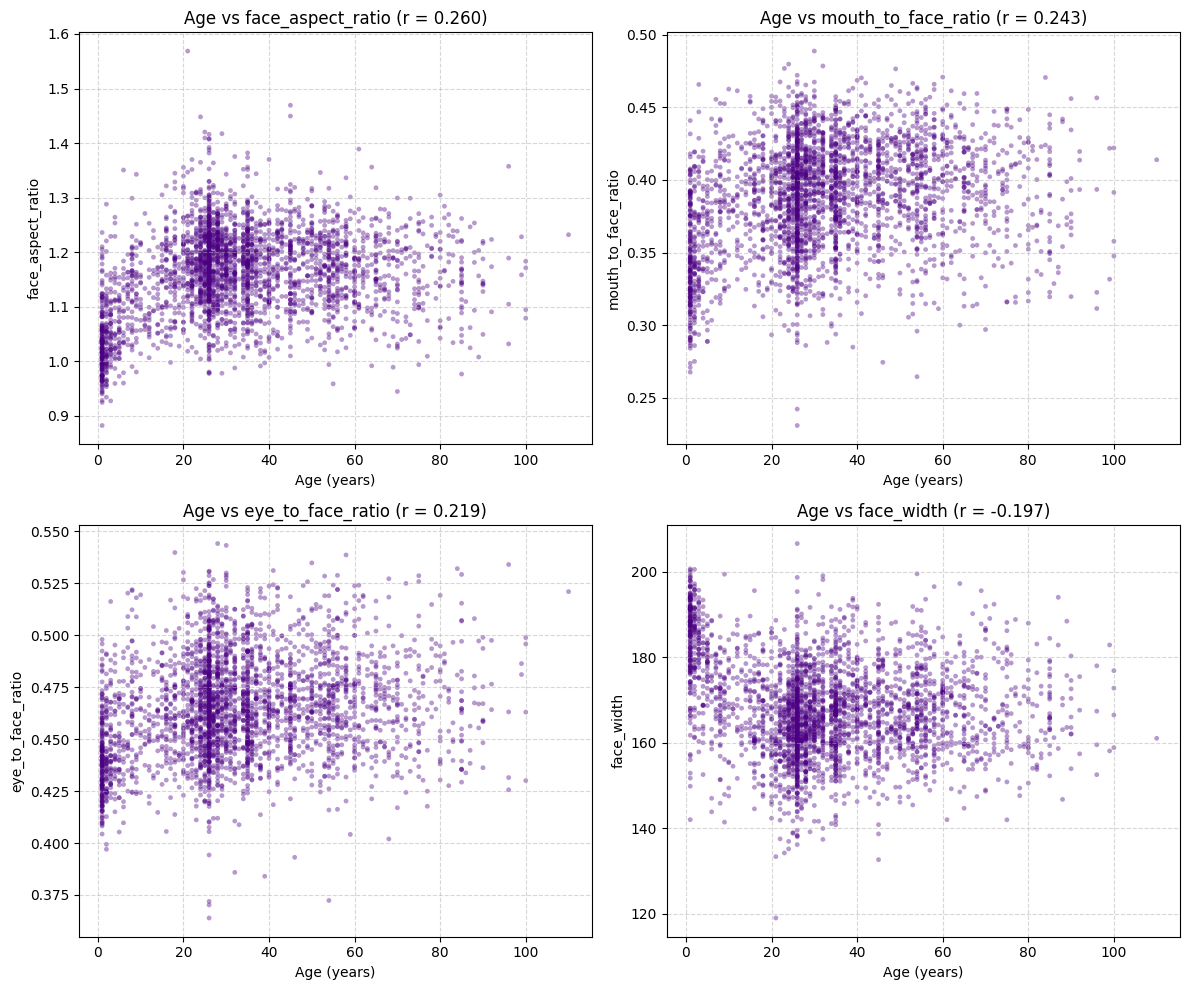

In [5]:
# Top 4 features with strongest correlation magnitude from Phase 11
top4_features = ['face_aspect_ratio', 'mouth_to_face_ratio', 'eye_to_face_ratio', 'face_width']

# Create 2x2 grid of scatter plots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for idx, feat in enumerate(top4_features):
    ax = axes[idx // 2, idx % 2]
    r_val = df[feat].corr(df['age'])
    ax.scatter(df['age'], df[feat], alpha=0.4, s=12, color='indigo', edgecolors='none')
    ax.set_title(f"Age vs {feat} (r = {r_val:.3f})")
    ax.set_xlabel("Age (years)")
    ax.set_ylabel(feat)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

# Save figure to PNG
plt.savefig("visualizations/04_age_vs_features_scatter.png", dpi=150)
plt.show()

### Observation: Age vs. Facial Features Scatter Analysis

*Placeholder for user observations on scatter plots:*
- [Examine visual patterns across Age vs `face_aspect_ratio` ($r=0.254$), `mouth_to_face_ratio` ($r=0.241$), `eye_to_face_ratio` ($r=0.212$), and `face_width` ($r=-0.186$).]
- [Note whether relationships appear weak, linear, or non-linear.]
- **Reminder:** Observed correlation coefficients indicate statistical association strength only, **not causation**.

In [10]:
# 6 key numeric features for distribution histograms
six_features = ['eye_distance', 'mouth_width', 'face_width', 'face_height', 'face_aspect_ratio', 'eye_to_face_ratio']

# Print exact skewness values before plotting
print("=== NUMERIC FEATURE SKEWNESS VALUES ===")
print(df[six_features].skew())

# Create 2x3 grid of histograms
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for idx, feat in enumerate(six_features):
    ax = axes[idx // 3, idx % 3]
    ax.hist(df[feat], bins=25, color='teal', edgecolor='black', alpha=0.7)
    sk = df[feat].skew()
    ax.set_title(f"{feat}\n(skew = {sk:.3f})")
    ax.set_xlabel(feat)
    ax.set_ylabel("Count")
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

# Save figure to PNG
plt.savefig("visualizations/05_feature_distributions.png", dpi=150)
plt.show()

=== NUMERIC FEATURE SKEWNESS VALUES ===
eye_distance        -0.278872
mouth_width         -0.159497
face_width           0.212498
face_height         -0.728841
face_aspect_ratio   -0.128102
eye_to_face_ratio    0.161449
dtype: float64


### Observation: Feature Distributions & Skewness

*Placeholder for user observations on numeric feature distributions:*
- [Discuss distribution spread, central tendency, outliers, and skewness for `eye_distance` (-0.347), `mouth_width` (-0.183), `face_width` (0.152), `face_height` (-0.786), `face_aspect_ratio` (-0.010), and `eye_to_face_ratio` (0.120) using the printed skewness values.]